# 4. Evaluation

Imports

In [68]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import mutual_info_score
from sklearn.linear_model import LogisticRegression

Data

In [70]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [71]:
def to_snake_case(col: str) -> str:
    col = list(col.strip().replace(" ", "_"))
    indexes = []

    for i in range(len(col)):
        if i > 0 and col[i].isupper():
            indexes.append(i)

    for i, ind in enumerate(indexes):
        col.insert(ind + i, "_")

    return "".join(col).lower()


df.columns = df.rename(
    columns={"customerID": "customer_id", "StreamingTV": "streaming_tv"}
).columns
df.columns = [to_snake_case(col) for col in df.columns]
df.head().T

,0,1,2,3,4
customer_id,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
senior_citizen,0,0,0,0,0
partner,Yes,No,No,No,No
dependents,No,No,No,No,No
tenure,1,34,2,45,2
phone_service,No,Yes,Yes,No,Yes
multiple_lines,No phone service,No,No,No phone service,No
internet_service,DSL,DSL,DSL,DSL,Fiber optic
online_security,No,Yes,Yes,Yes,No


In [72]:
df.total_charges = pd.to_numeric(df.total_charges, errors="coerce").fillna(0)
df.churn = (df.churn == "Yes").astype(int)
df[["total_charges", "churn"]]

,total_charges,churn
0,29.85,0
1,1889.50,0
2,108.15,1
3,1840.75,0
4,151.65,1
...,...,...
7038,1990.50,0
7039,7362.90,0
7040,346.45,0
7041,306.60,1


In [73]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_full_train = df_full_train.churn.values
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train["churn"]
del df_val["churn"]
del df_test["churn"]

In [74]:
numerical = ["tenure", "monthly_charges", "total_charges"]
categorical = [
    "gender",
    "senior_citizen",
    "partner",
    "dependents",
    "phone_service",
    "multiple_lines",
    "internet_service",
    "online_security",
    "online_backup",
    "device_protection",
    "tech_support",
    "streaming_tv",
    "streaming_movies",
    "contract",
    "paperless_billing",
    "payment_method",
]

Training and accuracy

In [75]:
dv = DictVectorizer()

train_dict = df_train[categorical + numerical].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [76]:
val_dict = df_val[categorical + numerical].to_dict(orient="records")
X_val = dv.transform(val_dict)

y_pred = model.predict_proba(X_val)[:, 1]
churn_desicion = y_pred >= 0.5
(y_val == churn_desicion).mean()

np.float64(0.8034066713981547)

In [77]:
model.predict_proba(X_val[8])[:, 1]

array([0.59494393])

4.2 Accuracy and Dummy Model

In [78]:
(y_val == churn_desicion).sum(), len(y_val)

(np.int64(1132), 1409)

In [79]:
1132 / 1409

0.8034066713981547

In [80]:
from sklearn.metrics import accuracy_score

In [81]:
thresholds = np.linspace(0, 1, 21)
thresholds_dict = {}

for t in thresholds:
    thresholds_dict[t] = accuracy_score(y_val, y_pred >= t)

print(
    *[f"{k} - {v}" for k, v in sorted(thresholds_dict.items(), reverse=True, key=lambda n: n[1])],
    sep="\n",
)

0.5 - 0.8034066713981547
0.55 - 0.8019872249822569
0.6000000000000001 - 0.7955997161107168
0.45 - 0.7913413768630234
0.65 - 0.7885024840312278
0.4 - 0.7821149751596878
0.35000000000000003 - 0.7665010645848119
0.7000000000000001 - 0.765791341376863
0.30000000000000004 - 0.758694109297374
0.75 - 0.7423704755145494
0.25 - 0.7345635202271115
0.8 - 0.7295954577714692
0.8500000000000001 - 0.7260468417317246
0.9 - 0.7260468417317246
0.9500000000000001 - 0.7260468417317246
1.0 - 0.7260468417317246
0.2 - 0.7026259758694109
0.15000000000000002 - 0.6614620298083748
0.1 - 0.6068133427963094
0.05 - 0.5124201561391057
0.0 - 0.2739531582682754


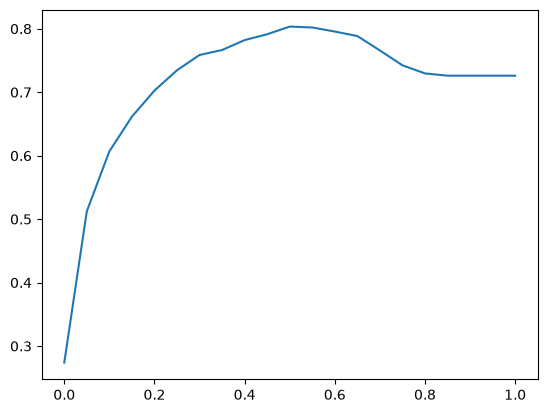

In [82]:
plt.plot(thresholds_dict.keys(), thresholds_dict.values())

In [83]:
from collections import Counter

In [84]:
Counter(y_pred >= 1.0), Counter(y_val)

(Counter({np.False_: 1409}), Counter({np.int64(0): 1023, np.int64(1): 386}))

## 4.3 Confusion Table

In [85]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)
actual_positive.sum(), actual_negative.sum()

(np.int64(386), np.int64(1023))

In [86]:
t = 0.5
predict_positive = (y_pred >= 0.5)
predict_negative = (y_pred < 0.5)
predict_positive.sum(), predict_negative.sum()

(np.int64(315), np.int64(1094))

In [87]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()
tp, tn

(np.int64(212), np.int64(920))

In [88]:
fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()
fp, fn

(np.int64(103), np.int64(174))

In [89]:
confusion_matrix = np.array(
    [
        [tn, fp],
        [fn, tp],
    ]
)
confusion_matrix

array([[920, 103],
       [174, 212]])

In [90]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

## 4.4 Precision and Recall

In [91]:
acc = (tp + tn) / (tp + tn + fp + fn)
acc

np.float64(0.8034066713981547)

Precicsion

In [92]:
p = tp / (tp + fp)
p

np.float64(0.6730158730158731)

Recall

In [93]:
r = tp / (tp + fn)
r


np.float64(0.5492227979274611)

## 4.5 ROC Curves

In [94]:
tpr = tp / (tp + fn)
fpr = fp / (fp + tn)
tpr, fpr

(np.float64(0.5492227979274611), np.float64(0.10068426197458455))

In [95]:
thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()
    
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tn, fp, fn, tp))

In [96]:
df_scores = pd.DataFrame(scores, columns=["threshold", "tn", "fp", "fn", "tp"])
df_scores["tpr"] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores["fpr"] = df_scores.fp / (df_scores.fp + df_scores.tn)
df_scores[::10]

,threshold,tn,fp,fn,tp,tpr,fpr
0,0.0,0,1023,0,386,1.000000,1.000000
10,0.1,489,534,20,366,0.948187,0.521994
20,0.2,651,372,47,339,0.878238,0.363636
30,0.3,777,246,94,292,0.756477,0.240469
40,0.4,848,175,132,254,0.658031,0.171065
50,0.5,920,103,174,212,0.549223,0.100684
60,0.6,970,53,235,151,0.391192,0.051808
70,0.7,1010,13,317,69,0.178756,0.012708
80,0.8,1023,0,381,5,0.012953,0.000000
90,0.9,1023,0,386,0,0.000000,0.000000


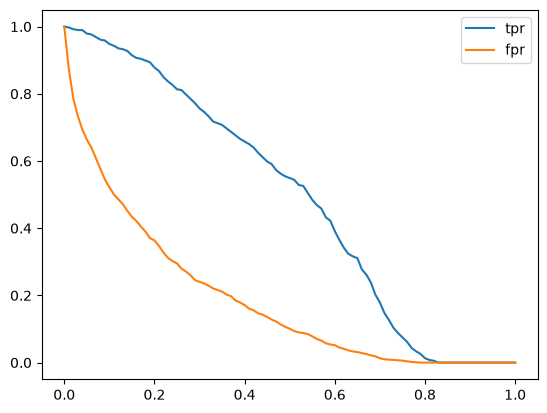

In [97]:
plt.plot(df_scores.threshold, df_scores.tpr, label="tpr")
plt.plot(df_scores.threshold, df_scores.fpr, label="fpr")
plt.legend()

Random model

In [98]:
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

In [99]:
def tpr_fpr_dataframe(y_val, y_pred):
    thresholds = np.linspace(0, 1, 101)
    scores = []

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)
        
        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
        
        scores.append((t, tn, fp, fn, tp))
        
    df_scores = pd.DataFrame(scores, columns=["threshold", "tn", "fp", "fn", "tp"])
    df_scores["tpr"] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores["fpr"] = df_scores.fp / (df_scores.fp + df_scores.tn)
    
    return df_scores

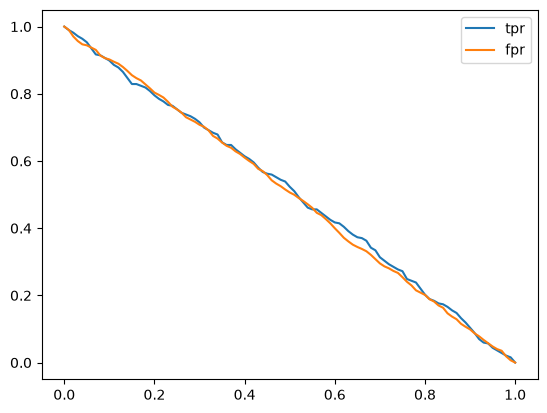

In [100]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)
plt.plot(df_rand.threshold, df_rand.tpr, label="tpr")
plt.plot(df_rand.threshold, df_rand.fpr, label="fpr")
plt.legend()

Ideal model

In [101]:
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()
num_neg, num_pos

(np.int64(1023), np.int64(386))

In [102]:
y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [103]:
y_ideal_predictions = np.linspace(0, 1, len(y_val))

In [104]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [105]:
((y_ideal_predictions >= 0.726) == y_ideal).mean()

np.float64(1.0)

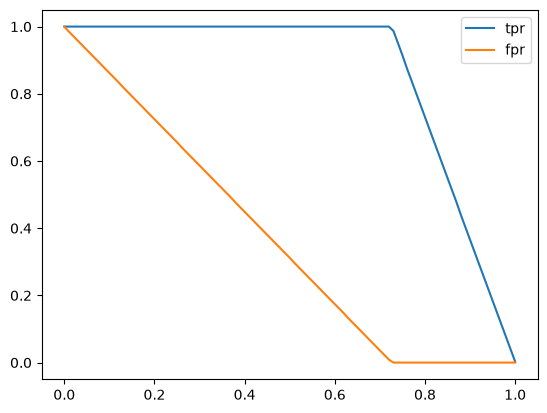

In [106]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_predictions)
plt.plot(df_ideal.threshold, df_ideal.tpr, label="tpr")
plt.plot(df_ideal.threshold, df_ideal.fpr, label="fpr")
plt.legend()

Putting everything together

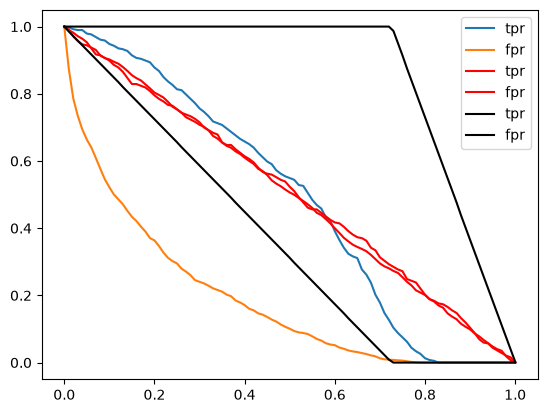

In [107]:
plt.plot(df_scores.threshold, df_scores.tpr, label="tpr")
plt.plot(df_scores.threshold, df_scores.fpr, label="fpr")

plt.plot(df_rand.threshold, df_rand.tpr, label="tpr", color="red")
plt.plot(df_rand.threshold, df_rand.fpr, label="fpr", color="red")

plt.plot(df_ideal.threshold, df_ideal.tpr, label="tpr", color="black")
plt.plot(df_ideal.threshold, df_ideal.fpr, label="fpr", color="black")
plt.legend()

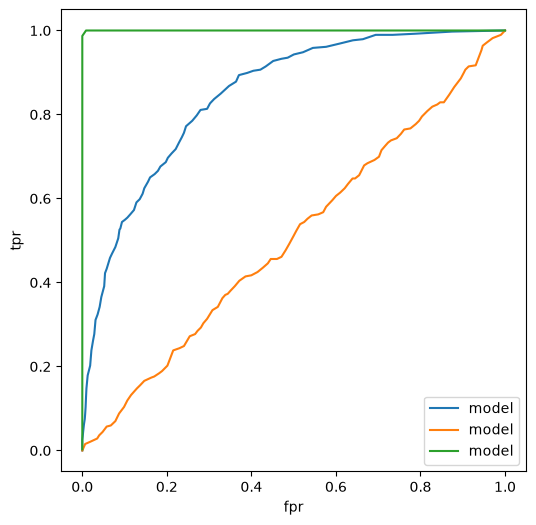

In [108]:
plt.figure(figsize=(6, 6))

plt.plot(df_scores.fpr, df_scores.tpr, label="model")
plt.plot(df_rand.fpr, df_rand.tpr, label="model")
plt.plot(df_ideal.fpr, df_ideal.tpr, label="model")

plt.xlabel("fpr")
plt.ylabel("tpr")

plt.legend()

In [109]:
from sklearn.metrics import roc_curve

In [110]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

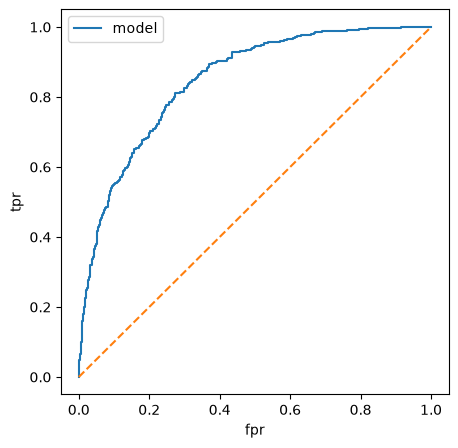

In [111]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label="model")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("fpr")
plt.ylabel("tpr")

plt.legend()

## 4.6 ROC AUC

In [112]:
from sklearn.metrics import auc

In [113]:
auc(fpr, tpr), auc(df_scores.fpr, df_scores.tpr)

(0.8463272200527758, 0.846025861152052)

In [114]:
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [115]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
auc(fpr, tpr)

0.8463272200527758

In [116]:
from sklearn.metrics import roc_auc_score

In [117]:
roc_auc_score(y_val, y_pred)

0.8463272200527758

In [118]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

In [119]:
import random

In [120]:
pos_ind = random.randint(0, len(pos) - 1)
neg_ind = random.randint(0, len(neg) - 1)

In [121]:
n, success = 10000, 0

for i in range(n):
    pos_ind = random.randint(0, len(pos) - 1)
    neg_ind = random.randint(0, len(neg) - 1)
    
    if pos[pos_ind] > neg[neg_ind]:
        success += 1
        
success / n

0.8445

In [122]:
n = 50000

np.random.seed(1)
pos_ind = np.random.randint(0, len(pos), size=n)
neg_ind = np.random.randint(0, len(neg), size=n)

(pos[pos_ind] > neg[neg_ind]).mean()

np.float64(0.84906)

## 4.7 Cross-Validation

In [141]:
def train(df, y_train, C=1.0):
    dicts = df[categorical + numerical].to_dict(orient="records")
    
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)
    
    model = LogisticRegression(C=C, max_iter=10000)
    model.fit(X_train, y_train)
    
    return dv, model
    

In [142]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient="records")
    
    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]
    
    return y_pred

In [143]:
dv, model = train(df_train, y_train, C=10)
y_pred = predict(df_val, dv, model)
y_pred

array([0.18306267, 0.00489597, 0.65033327, 0.07596568, 0.58783462,
       0.29025296, 0.28379098, 0.23856823, 0.00269662, 0.08339818,
       0.04983929, 0.01212577, 0.4846209 , 0.72918236, 0.34310076,
       0.19433235, 0.64230037, 0.2805546 , 0.28482444, 0.03028921,
       0.67006681, 0.02389959, 0.00287781, 0.49290294, 0.74146807,
       0.08410079, 0.72155567, 0.02829203, 0.67015228, 0.00987491,
       0.03688127, 0.0081857 , 0.43784681, 0.57174149, 0.1316058 ,
       0.03032971, 0.51645919, 0.14993975, 0.76412715, 0.60674713,
       0.31786079, 0.289458  , 0.73810721, 0.00707356, 0.00194025,
       0.57091912, 0.41891572, 0.30489354, 0.0864117 , 0.48496516,
       0.00750313, 0.00613882, 0.55109271, 0.59541333, 0.2044066 ,
       0.08426148, 0.00471408, 0.42898488, 0.01960073, 0.00376115,
       0.01823863, 0.70005702, 0.27503719, 0.06343922, 0.64133521,
       0.03030696, 0.72350572, 0.07792248, 0.18254526, 0.01581499,
       0.44696942, 0.39017221, 0.51490521, 0.19714551, 0.70257

In [144]:
from sklearn.model_selection import KFold

In [145]:
kfold = KFold(n_splits=10, shuffle=True, random_state=1)

In [152]:
n_splits = 5

for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]
        
        y_train = df_train.churn.values
        y_val = df_val.churn.values
        
        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)
        
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
        
    print(f"{np.mean(scores)} +- {np.std(scores)}, C = {C}")

0.8250684584125745 +- 0.00928320336814489, C = 0.001
0.8399527427063243 +- 0.008235658006889298, C = 0.01
0.841870829966315 +- 0.0072342930187319285, C = 0.1
0.8419397414804113 +- 0.006870623407195754, C = 0.5
0.8418460182682992 +- 0.0069071206359891, C = 1
0.8417470148146423 +- 0.0068303019423654665, C = 5
0.8417855457979412 +- 0.0067108721219644495, C = 10


In [155]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1)
y_pred = predict(df_test, dv, model)
        
auc = roc_auc_score(y_test, y_pred)
auc

0.8584032088573997